<a href="https://colab.research.google.com/github/aaneriC/Computer-Vision/blob/main/MachineLearningYOLO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Go Runtime -> change runtime type -> T4 GPU**

Verify NVIDIA GPU Availability (Tesla T4 or similar)

In [ ]:
!nvidia-smi

Mon Apr 27 00:55:08 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   32C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

Upload data.zip and place it under notebook drive: /content

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!cp /content/drive/MyDrive/MLData/data.zip /content

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


**Split the imported data.zip into train and validation folders**

1. Unzip the data.zip, create and place unzipped file into a new folder, custom_data

In [ ]:
!unzip -q /content/data.zip -d /content/custom_data

2. Get and run python script that creates and randomizes the data set



*   Script will create a folder called "data" with two subfolders: "train" and "validation"
*   Script will randomize the imported data set



In [ ]:
!wget -O /content/train_val_split.py https://raw.githubusercontent.com/EdjeElectronics/Train-and-Deploy-YOLO-Models/refs/heads/main/utils/train_val_split.py

# TO DO: Improve robustness of train_val_split.py script so it can handle nested data folders, etc
!python train_val_split.py --datapath="/content/custom_data" --train_pct=0.9

--2026-04-27 00:56:00--  https://raw.githubusercontent.com/EdjeElectronics/Train-and-Deploy-YOLO-Models/refs/heads/main/utils/train_val_split.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 3203 (3.1K) [text/plain]
Saving to: ‘/content/train_val_split.py’

/content/train_val_ 100%[===================>]   3.13K  --.-KB/s    in 0s      

2026-04-27 00:56:00 (37.2 MB/s) - ‘/content/train_val_split.py’ saved [3203/3203]

Number of image files: 50
Number of annotation files: 50
Images moving to train: 45
Images moving to validation: 5


**Configure Training**


Creating a YAML file
*   Specifies location of train and validation data
*   Defines model's classes


---




1. Define a function that creates the YAML file


In [ ]:
import yaml
import os

def create_data_yaml(path_to_classes_txt, path_to_data_yaml):

  # Read class.txt to get class names
  if not os.path.exists(path_to_classes_txt):
    print(f'classes.txt file not found! Please create a classes.txt labelmap and move it to {path_to_classes_txt}')
    return
  with open(path_to_classes_txt, 'r') as f:
    classes = []

    for line in f.readlines():
      if len(line.strip()) == 0: continue
      classes.append(line.strip())
  number_of_classes = len(classes)

  # Create data dictionary
  data = {
      'path': '/content/data',
      'train': 'train/images',
      'val': 'validation/images',
      'nc': number_of_classes,
      'names': classes
  }
  # Write data to YAML file
  with open(path_to_data_yaml, 'w') as f:
    yaml.dump(data, f, sort_keys=False)
  print(f'Created config file at {path_to_data_yaml}')

  return


2. Create variables for the previously defined function, create_data_yaml(), then call it

In [ ]:
# Define path to classes.txt and run function
path_to_classes_txt = '/content/custom_data/classes.txt'
path_to_data_yaml = '/content/data.yaml'

create_data_yaml(path_to_classes_txt, path_to_data_yaml)

print('\nFile contents:\n')
!cat /content/data.yaml

Created config file at /content/data.yaml

File contents:

path: /content/data
train: train/images
val: validation/images
nc: 14
names:
- BG_base_correct
- BG_base_incorrect
- BG_cover_correct
- BG_cover_incorrect
- CPP_logo_correct
- CPP_logo_incorrect
- XV_cylinder_correct
- XV_cylinder_incorrect
- acrylic_block_correct
- acrylic_block_incorrect
- base_w_hole_correct
- base_w_hole_incorrect
- brass_correct
- brass_incorrect


**Train the model**
1. Run install for Ultralytics

Ultralytics will allow us to import YOLO model

In [ ]:
!pip install ultralytics
from ultralytics import YOLO

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 32.8 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


2. Set up the model and input parameters for training -> begin training


*   We will declare model and use YOLO11 nano segmentation
*   we declare 'results,' which will be used to define the parameters below


---



***What each parameter means:***

**data**: tells the model where to find your training and validation images, and how many classes it needs to detect

**epochs**: How many pass throughs for the entire training set.
*   Training for 100 epochs means the model will "study" the 40 images 100 times

**imgsz**: tells the model what to resize all dataset images to

**batch**: how many images the model processes simultaneously before updating weights and biases


**name**: folder to be created under project

**project**: where results are stored

*   Collect weight, graphs, and logs

**device**: tell model use first available GPU

**patience**: If model doesn't improve accuracy at the specified number, then stop training

**plots**: specify whether or not you want to generate and save charts


*   Loss curves and confusion matrices -- tells us how well its learning








In [ ]:
model = YOLO("yolo11s-seg.pt")

results = model.train(
    data="/content/data.yaml",
    epochs=100,
    patience=50,
    imgsz=1024,
    batch=8,
    name="yolo11small_seg_run", #define folder where weights are held
    project="/content/drive/MyDrive/yolo11_runs", #define the overall folder
    device=0,
    plots=True,
    amp=True,
    mosaic=1.0
)

Ultralytics 8.4.41 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1024, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11small_seg_run, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience

**Test the model**
1. Call the trained model

In [ ]:
model = YOLO("/content/drive/MyDrive/yolo11_runs/yolo11small_seg_run/weights/best.pt")

2. Test the model on the images in validation folder

In [ ]:
results = model.predict(
    source="/content/data/validation/images",
    conf=0.6,
    save=True,
    save_txt=True,
    project="/content/drive/MyDrive/yolo11_runs",
    name="validation_preds"
)


image 1/10 /content/data/validation/images/42144d77-20260416_222041770_iOS.jpg: 512x1024 1 BG_base_incorrect, 1 BG_cover_correct, 1 CPP_logo_correct, 1 XV_cylinder_correct, 1 acrylic_block_incorrect, 1 base_w_hole_correct, 1 brass_correct, 25.1ms
image 2/10 /content/data/validation/images/539dc90a-IMG_5965.jpg: 736x1024 1 BG_base_correct, 1 BG_cover_correct, 1 CPP_logo_correct, 1 XV_cylinder_correct, 1 acrylic_block_correct, 1 base_w_hole_correct, 1 brass_correct, 34.3ms
image 3/10 /content/data/validation/images/65c61692-IMG_5972.jpg: 640x1024 1 BG_base_incorrect, 1 BG_cover_correct, 1 CPP_logo_correct, 1 XV_cylinder_correct, 1 acrylic_block_correct, 1 base_w_hole_correct, 1 brass_correct, 27.6ms
image 4/10 /content/data/validation/images/8cb0dfe2-20260416_222040105_iOS.jpg: 608x1024 1 BG_base_incorrect, 1 BG_cover_correct, 1 CPP_logo_correct, 1 XV_cylinder_correct, 1 acrylic_block_incorrect, 1 base_w_hole_correct, 1 brass_correct, 27.0ms
image 5/10 /content/data/validation/images/af

3. Display all images that the model annotated

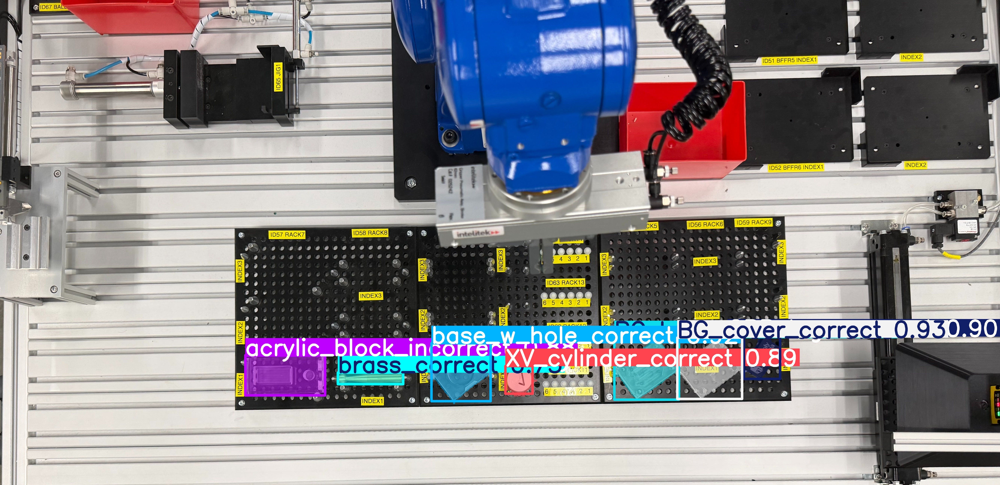

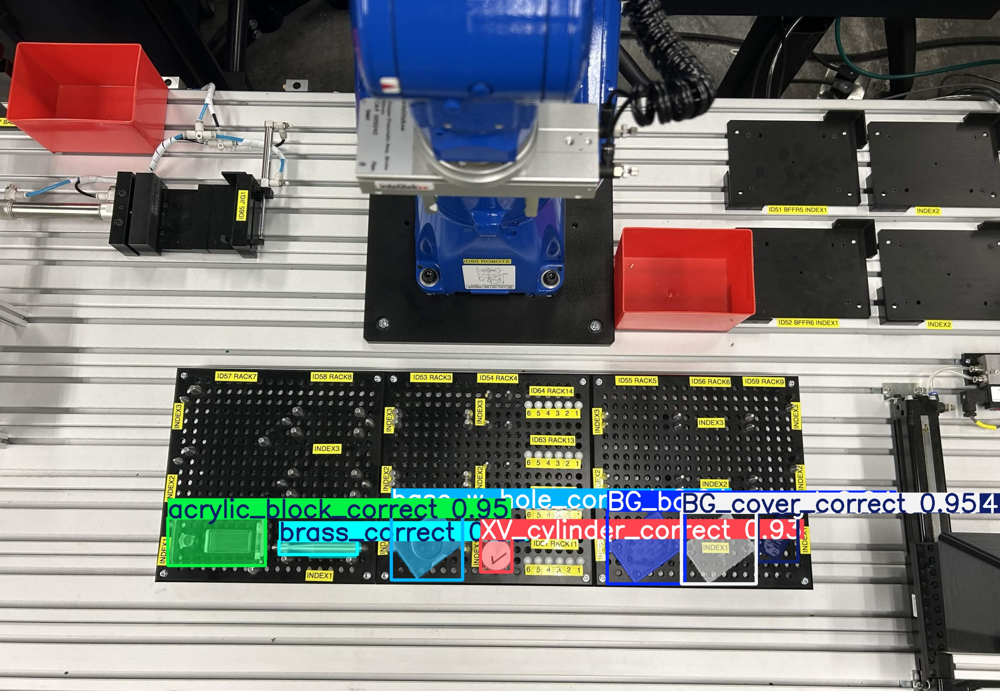

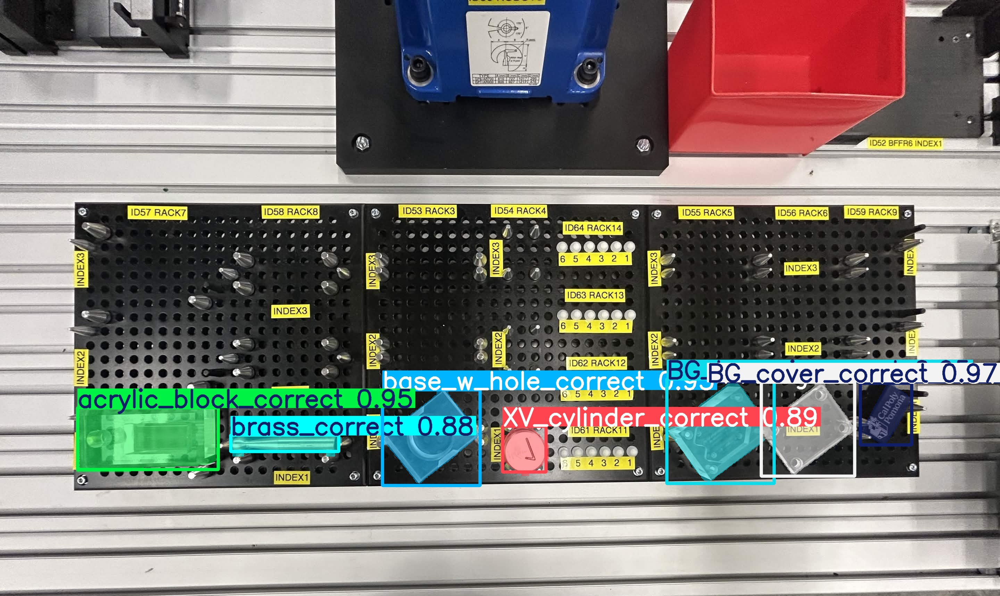

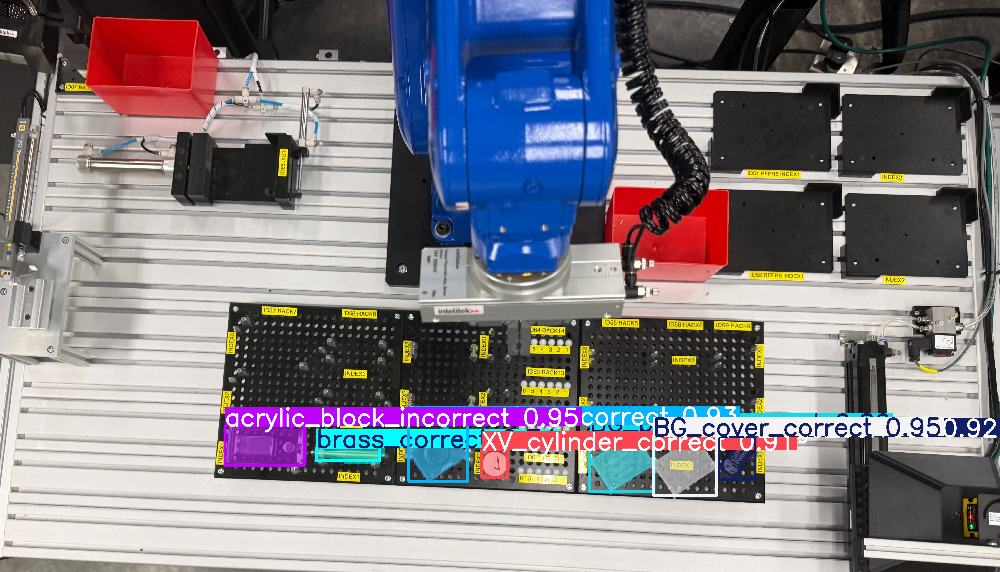

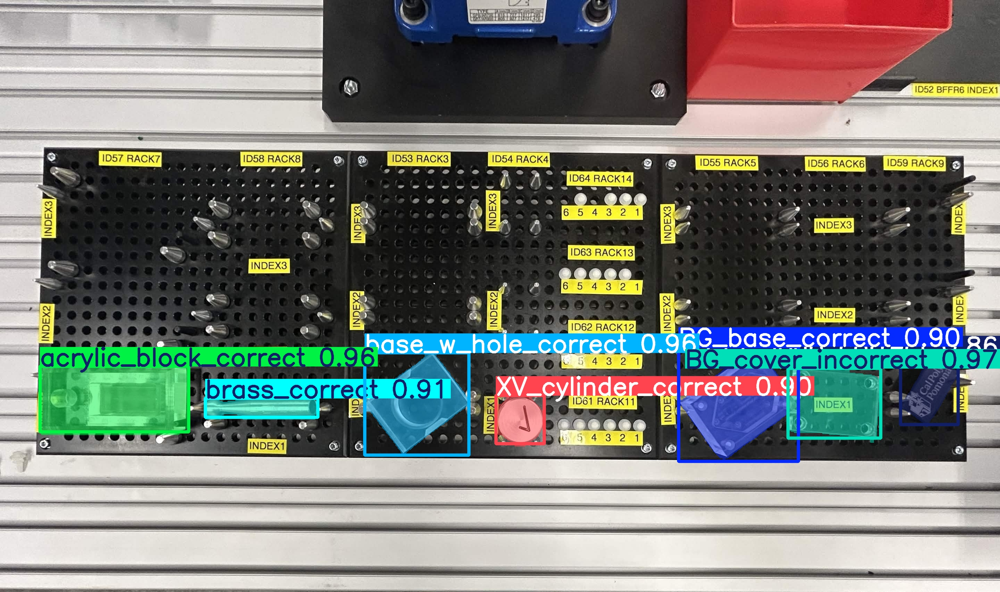

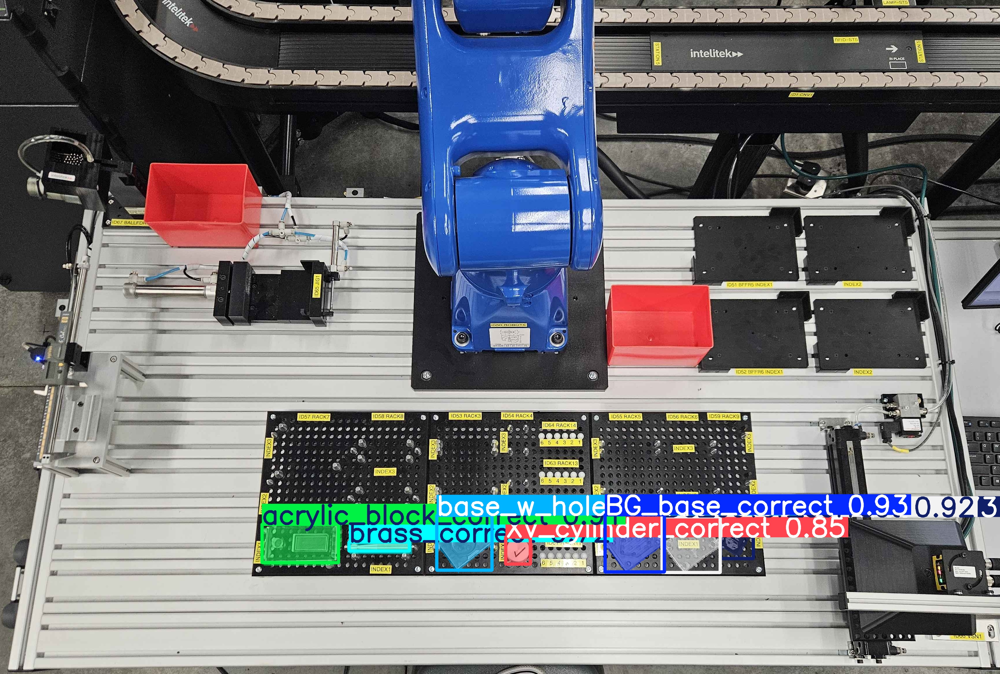

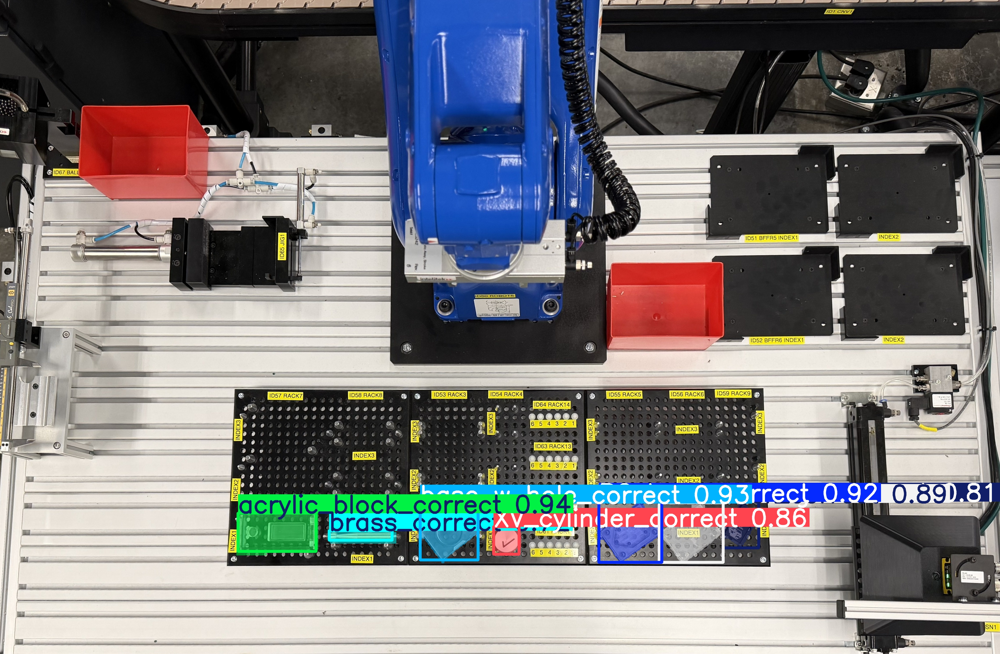

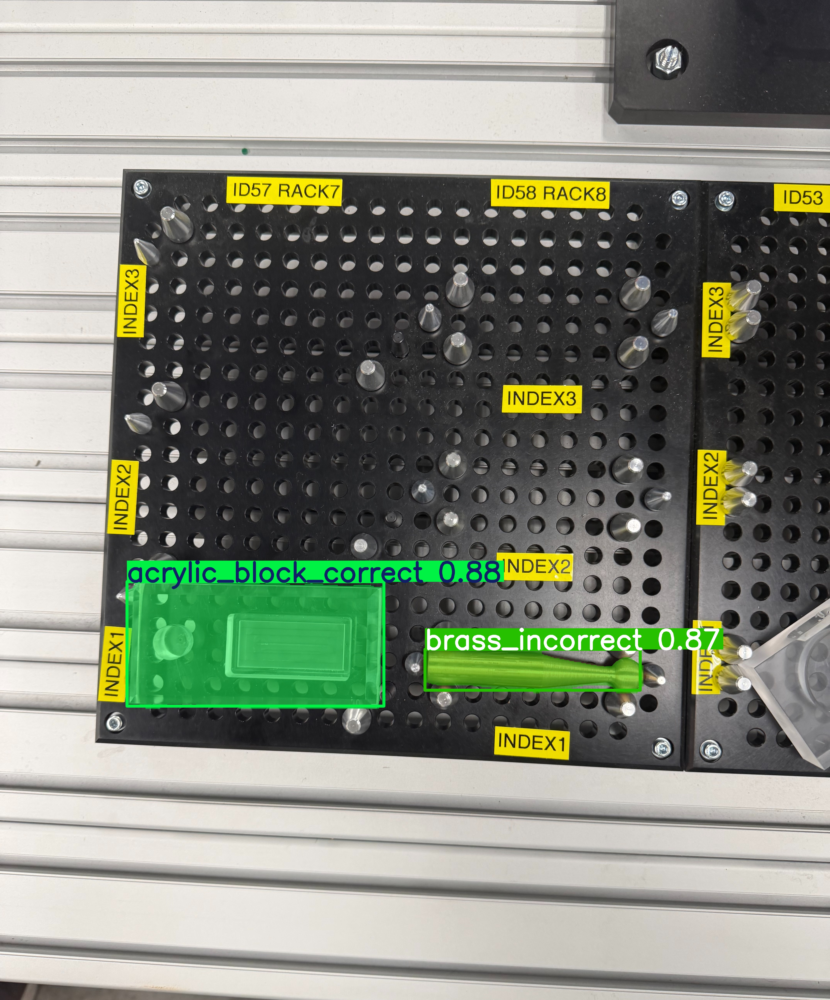

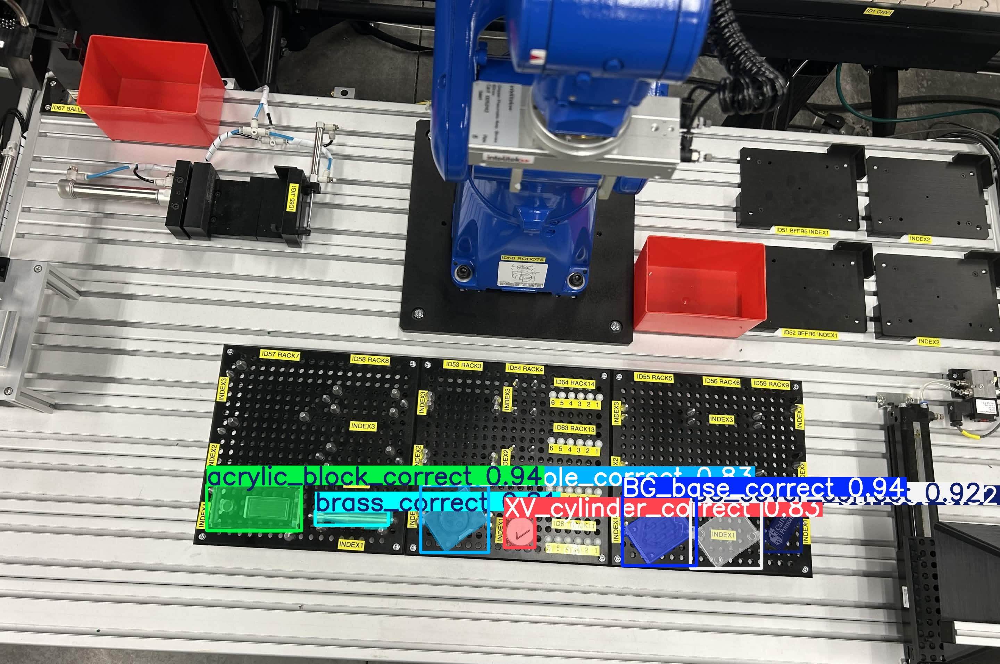

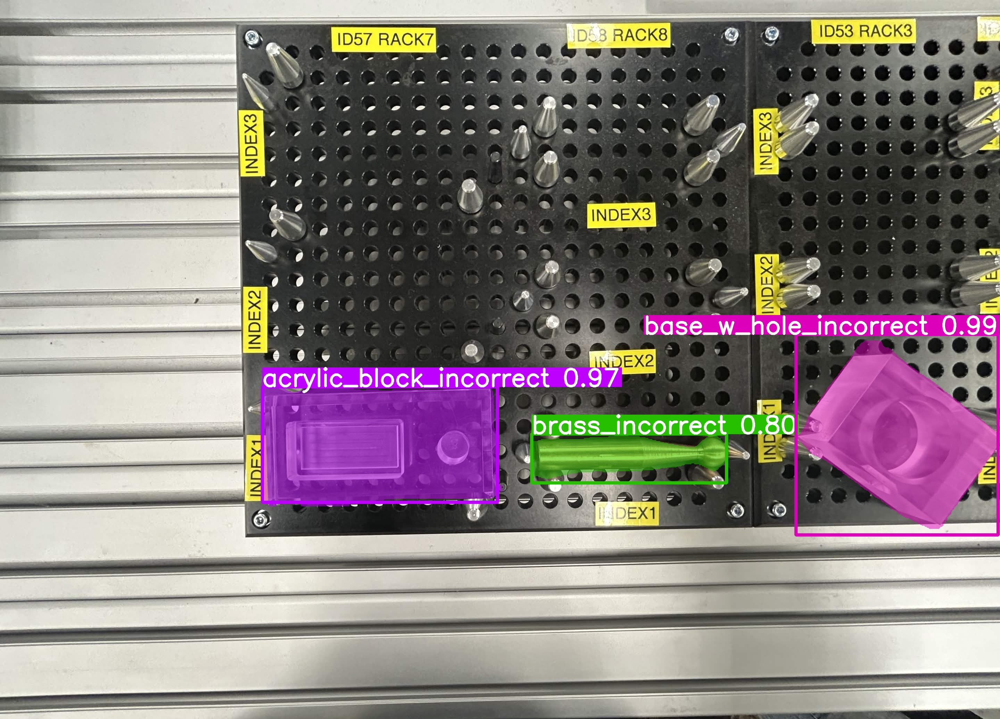

In [ ]:
import glob
from IPython.display import Image, display

for img_path in glob.glob("/content/drive/MyDrive/yolo11_runs/validation_preds-3/*.jpg"):
    display(Image(filename = img_path, height= 400))